In [1]:
pip install scikit_posthocs 

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://pypi.yandex-team.ru/simple
Note: you may need to restart the kernel to use updated packages.


In [2]:
#Нафига мы это делаем
# Померяли по kruskal - где-то есть разница, но непонятно, где именно.  
# scikit_posthocs тыкает в каждую группу пальцем и орет: "ЭТО ТЫ ВИНОВАТ В p < 0.05?!" И они отвечают
# (короче, ищем, кто конкретно отличается от других и как сильно  

In [3]:
import pandas as pd #для всего
import seaborn as sns #для графиков
import matplotlib.pyplot as plt #тоже для графиков
import numpy as np #для генерации чисел, например
#эти библиотеки нужны для статистических тестов, если собранные группы трудно сравнивать, например, они разного размера
from scipy.stats import kruskal
from scikit_posthocs import posthoc_dunn

In [4]:
df=pd.read_excel('mock.xlsx')
df.head()

,country_name,skills,tone_value
0,Конго,Разработка,0
1,Россия,Софтскиллы,2
2,Конго,Бухгалтерия,0
3,Сербия,Разработка,0
4,Конго,Бухгалтерия,1


In [5]:
print(f'общий объем массива:{len(df)}')

общий объем массива:4272


In [6]:
#объем записей по формам/периодам
df.groupby('country_name')['skills'].count()

country_name
Ангола          183
Кипр            304
Конго           313
Кот Д'Ивуар     870
Нигер           725
Россия         1069
Сербия          505
Турция          303
Name: skills, dtype: int64

In [7]:
#выборки по странам очень разного размера
#непараметрические тесты менее чувствительны к неравным объемам  =>> делаем Данна: он не парится про размеры выборок

In [8]:
# Создаем копию для безопасной работы
df2 = df.copy()

groups = {}
for form in df["country_name"].unique():
    groups[form] = df[df["country_name"] == form]["tone_value"].values
    

# 1. Тест Крускала-Уоллиса
H, p_kruskal = kruskal(*groups.values())
print(f"Kruskal-Wallis: p-value = {p_kruskal:.4f}")

# 2. Тест Данна (если p_kruskal < 0.05)
if p_kruskal < 0.05:
    dunn_result = posthoc_dunn(
        [groups[year] for year in sorted(groups.keys())],
        p_adjust='bonferroni'
    )
    print("\nDunn test (with Bonferroni correction):")
    print(dunn_result)
    
    # Сопоставление групп с реальными названиями форм
form_names = sorted(df['country_name'].unique())
group_mapping = {i+1: name for i, name in enumerate(form_names)}

print("\nСоответствие групп названиям форм:")
for group_id, form_name in group_mapping.items():
    print(f"Группа {group_id}: {form_name}")

# Переименовываем индексы и столбцы в результатах теста Данна
dunn_result.index = [group_mapping[i] for i in dunn_result.index]
dunn_result.columns = [group_mapping[i] for i in dunn_result.columns]

print("\nDunn test с названиями форм:")
print(dunn_result)

# Рассчитываем медианы по названиям форм 
median_tone = df2.groupby('country_name')['tone_value'].median()
# Сортируем по времени 
median_tone = median_tone.loc[form_names]

# Считаем распределение тональностей
tone_distribution = df.groupby(['country_name', 'tone_value']).size().unstack(fill_value=0)
total_counts = tone_distribution.sum(axis=1)
tone_percentages = tone_distribution.div(total_counts, axis=0) * 100

# Добавляем общее количество отзывов
tone_percentages['Total Reviews'] = total_counts

# Переименовываем тональности для понятности
tone_percentages = tone_percentages.rename(columns={
    0: 'Плохо (%)',
    1: 'Нормально (%)',
    2: 'Хорошо (%)'
})

# Сортируем по времени (если нужно)
tone_percentages = tone_percentages.sort_index()

print(tone_percentages)

Kruskal-Wallis: p-value = 0.0000

Dunn test (with Bonferroni correction):
              1             2         3         4             5             6  \
1  1.000000e+00  1.000000e+00  0.074998  0.000260  3.295453e-09  1.039694e-12   
2  1.000000e+00  1.000000e+00  1.000000  0.024548  2.242770e-07  1.921746e-11   
3  7.499783e-02  1.000000e+00  1.000000  1.000000  4.969845e-03  1.076173e-05   
4  2.604466e-04  2.454790e-02  1.000000  1.000000  1.694110e-02  2.217600e-06   
5  3.295453e-09  2.242770e-07  0.004970  0.016941  1.000000e+00  1.000000e+00   
6  1.039694e-12  1.921746e-11  0.000011  0.000002  1.000000e+00  1.000000e+00   
7  6.750035e-04  5.289294e-02  1.000000  1.000000  1.016865e-01  2.206640e-04   
8  1.000000e+00  1.000000e+00  0.942125  0.004349  1.490734e-08  5.920022e-13   

          7             8  
1  0.000675  1.000000e+00  
2  0.052893  1.000000e+00  
3  1.000000  9.421255e-01  
4  1.000000  4.348865e-03  
5  0.101687  1.490734e-08  
6  0.000221  5.920022e-13  


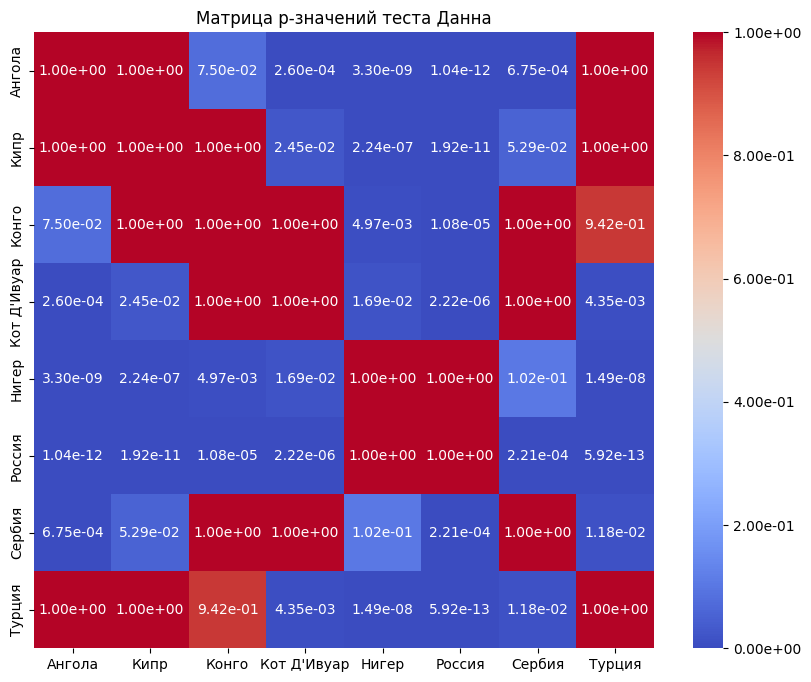

In [9]:
data_matrix = pd.DataFrame(dunn_result, index=dunn_result.keys())

# Создаём тепловую карту
plt.figure(figsize=(10, 8))
sns.heatmap(data_matrix, annot=True, fmt=".2e", cmap='coolwarm', cbar_kws={"format": "%.2e"})
plt.title('Матрица p-значений теста Данна')
plt.show()

In [10]:
#как это читать?
# Крускал-Уоллис: "Ребята, у вас тут, вы не поверите, какая разница!" (p=0.0000)
#
# Данн с поправкой Бонферрони уточняет:
# 🟦 Синие цифры (p < 0.05): "О, да вы реально разные!" 
#   - Россия vs все: "Я особенная!" (p=5.9e-13 с Турцией - рекорд!)
#   - Нигер vs Ангола: "Мы не братья!" (p=3.3e-09)
#
# 🟥 Красные цифры (p > 0.05): "Ну... может и одинаковые"
#   - Кипр vs Турция: "Близнецы-братья" (p=1.0)
#   - Конго vs Турция: "Ну почти одно и то же" (p=0.94)
#
# Тональности:
# Россия статистически уникальна и лидирует в негативе (63% - "всё плохо"), 
# Нигер грустит (58%), 
# Турция и 🇨🇾 Кипр - самые позитивные (15% - "норм")
#
# Вывод: данные кричат "Есть разница!"


In [11]:
df['skills'].unique()

array(['Разработка', 'Софтскиллы', 'Бухгалтерия', 'Процессы',
       'Разработка, Бухгалтерия', 'Бухгалтерия, Разработка',
       'Процессы, Разработка', 'Разработка, Найм',
       'Разработка, Быстрое обучение', 'Разработка, Нагрузка, Процессы',
       'Нагрузка, Бухгалтерия', 'Быстрое обучение',
       'Разработка, Процессы',
       'Разработка, Быстрое обучение, Бухгалтерия',
       'Разработка, Разработка', 'Быстрое обучение, Разработка',
       'Задачи, Разработка', 'Разработка, Нагрузка, Бухгалтерия',
       'Быстрое обучение, Бухгалтерия',
       'Разработка, Нагрузка, Корпоративная культура', 'Кризисменеджмент',
       'Процессы, Бухгалтерия', 'Разработка, Нагрузка',
       'Нагрузка, Управление ', 'Процессы, Задачи',
       'Разработка, Быстрое обучение, Бенефиты', 'Корпоративная культура',
       'Управление ', 'Разработка, Качество продуктов',
       'Разработка, Нагрузка, Разработка',
       'Бухгалтерия, Быстрое обучение',
       'Быстрое обучение, Корпоративная культура, 

In [12]:
#видим, кажется, полный бардак в данных про скиллы в таблице - комбинации скиллов через запятую

# "Бухгалтерия ×4" — либо опечатка, либо крик души ("Я УСТАЛ ОТ БУХГАЛТЕРИИ!")  
# "Разработка, Нагрузка, Нагрузка, Разработка" — классика: "Код → Дебаг → Стресс → Повторить" ♻️  
# "Пожалуйста, уточните запрос" — самый честный тег в датасете 🙃  
# "Корпоративная культура" и "Кризисменеджмент" в одном теге — либо сарказм, либо идеальное резюме 2024 года.  


In [13]:
#дропаем то, что не содержит перечисления скиллов, то есть ошибки разметки/заполнения
all_data=df
total_rows=len(df)
# Фильтрация строк, не содержащих буквосочетаний 'напиши' и 'напишите'
all_data = all_data[~all_data['skills'].str.contains(r'напиши|напишите', case=False, na=False)]
all_data = all_data[~all_data['skills'].str.contains(r'Сообщение|сообщение', case=False, na=False)]
all_data = all_data[~all_data['skills'].str.contains(r'уточните', case=False, na=False)]
all_data = all_data[~all_data['skills'].str.contains(r'Пожалуйста', case=False, na=False)]

# Количество строк после удаления
remaining_rows = len(all_data)

# Количество удалённых строк
deleted_rows = total_rows - remaining_rows

# Расчёт процента удалённых строк
deleted_percentage = (deleted_rows / total_rows) * 100

# Вывод результата
print(f"Удалено строк: {deleted_rows}")
print(f"Процент удалённых строк: {deleted_percentage:.2f}%")
print(len(all_data))

Удалено строк: 10
Процент удалённых строк: 0.23%
4262


In [14]:
#почистим еще немножко
all_data['skills'] = (
    all_data['skills']
    .str.replace(r'Ответ:', '', regex=True)  # Удаление 'Ответ:' как отдельного слова
    .str.replace(r'Кризисменеджменты', 'Кризисменеджмент', regex=True)    
    .str.replace(r'\n\nПроцессы', '', regex=True)   
    .str.replace(r'\n\nНагрузка','',regex=True)
    .str.replace(r'.','',regex=True)
)

In [15]:
# Разбираем "салат" из тегов на ингредиенты:
# Из столбца с кучей строк вида "Разработка, Бухгалтерия, Кризисменеджмент"
# делаем аккуратные бинарные столбцы для каждого навыка (1 - есть, 0 - нет)

# Теперь можно:
# 1. Считать корреляции с тональностью (грустит ли бухгалтерия больше разработчиков?)
# 2. Искать любовь между скиллами (если есть "Кризисменеджмент", то будет и "Нагрузка"?)
# 3. Вычислять: "Корпоративная культура" чаще с "Софтскиллами" или с "Управлением"?


dummy_df = all_data['skills'].str.get_dummies(sep=', ')
dummy_df.columns  # Смотрим, какие скиллы выжили после "демонстрации"


Index([' Бухгалтерия', 'Архитектура данных-бонус', 'Бенефиты', 'Бухгалтерия',
       'Быстрое обучение', 'Задачи', 'Качество продуктов',
       'Корпоративная культура', 'Кризисменеджмент', 'Мотивация', 'Нагрузка',
       'Найм', 'Обучение', 'Процессы', 'Разработка', 'Софтскиллы',
       'Управление '],
      dtype='object')

In [16]:
# 🧼 Чистим теги: "Бухгалтерия  " -> "Бухгалтерия" (пробелы - зло!)
# 🤼 Объединяем дубли: если где-то в строке есть 1 - оставляем 1 (правило жадности)
# 🏆 Фильтруем редкие теги: меньше 5 упоминаний? Не, не слышали
# 🧩 Собираем Frankenstein-датафрейм из того что осталось
# 🎉 Profit! Теперь можно искать, кто больше ноет - бухгалтеры или разработчики

dummy_df.columns = dummy_df.columns.str.strip()

# Объединяем исходный датафрейм с новыми бинарными столбцами
all_data = pd.concat([all_data, dummy_df], axis=1)

# Список колонок, которые нужно сохранить неизменными
fixed_columns = ['country_name',
    'skills',
    'tone_value'
]
# Извлекаем неизменные колонки
fixed_data = all_data[fixed_columns]

# Удаляем неизменные колонки и вычисляем суммы по оставшимся
remaining_data = all_data.drop(columns=fixed_columns)
column_sums = remaining_data.sum()
# Фильтруем колонки, оставляя только те, где сумма >= 5
filtered_columns = column_sums[column_sums >= 5].index

# Группируем отфильтрованные колонки по названиям и объединяем их
grouped_columns = remaining_data[filtered_columns].columns.to_series().groupby(remaining_data[filtered_columns].columns).groups

# Создаём новый датафрейм для объединённых колонок
combined_data = pd.DataFrame()

for column_name, column_indices in grouped_columns.items():
    # Выбираем колонки с одинаковым названием, используя их названия
    group = remaining_data[filtered_columns][list(column_indices)]
    
    # Применяем функцию max по строкам — если в строке есть хотя бы одна 1, результат будет 1
    combined_data[column_name] = group.max(axis=1)
    
# Объединяем неизменные колонки с объединёнными
new_data = pd.concat([fixed_data, combined_data], axis=1)

# Просмотр результата
print(new_data.head())    

  country_name       skills  tone_value  Бенефиты  Бухгалтерия  \
0        Конго   Разработка           0         0            0   
1       Россия   Софтскиллы           2         0            0   
2        Конго  Бухгалтерия           0         0            1   
3       Сербия   Разработка           0         0            0   
4        Конго  Бухгалтерия           1         0            1   

   Быстрое обучение  Задачи  Качество продуктов  Корпоративная культура  \
0                 0       0                   0                       0   
1                 0       0                   0                       0   
2                 0       0                   0                       0   
3                 0       0                   0                       0   
4                 0       0                   0                       0   

   Кризисменеджмент  Нагрузка  Найм  Процессы  Разработка  Софтскиллы  \
0                 0         0     0         0           1           0   
1     

In [17]:
# Первый взгляд на результат (спойлер: выглядит лучше, чем ожидалось)
new_data.columns

Index(['country_name', 'skills', 'tone_value', 'Бенефиты', 'Бухгалтерия',
       'Быстрое обучение', 'Задачи', 'Качество продуктов',
       'Корпоративная культура', 'Кризисменеджмент', 'Нагрузка', 'Найм',
       'Процессы', 'Разработка', 'Софтскиллы', 'Управление'],
      dtype='object')

<h2>Визуализация данных</h2>

In [18]:
# Когда HR говорит "Нам нужны универсалы", а данные показывают:
# - Россия: "Разработка+Нагрузка+Кризисменеджмент" (три в одном - как шампунь для депрессии)
# - Турция: "Софтскиллы+Быстрое обучение" (видимо, ищем не работников, а дзен-мастеров)
# - "Бухгалтерия" везде в топе - мир держится на бухгалтерах, но тональность "плохо" (совпадение? не думаю)

# Зачем это анализируем:
# 1. Узнать, в какой стране за "Нагрузку" хотя бы "нормально" платят
# 2. Найти аномалии: если "Корпоративная культура" и "хорошо" в одном графике - это или ошибка данных, или Google
# 3. Доказать, что "Быстрое обучение" обычно означает "Быстрое выгорание" 🔥


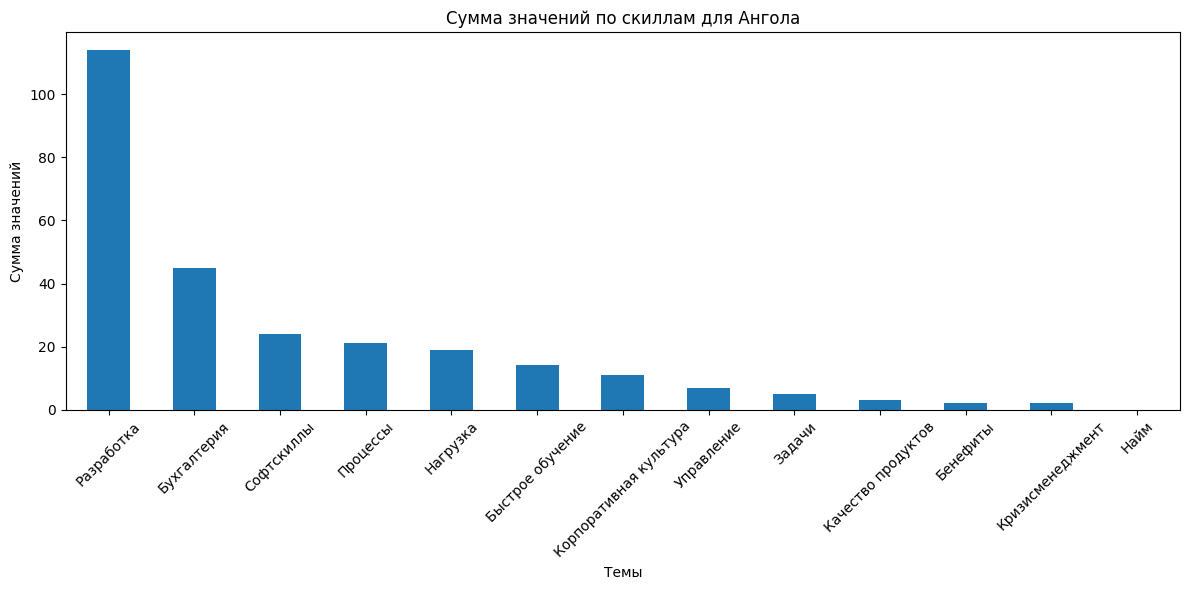

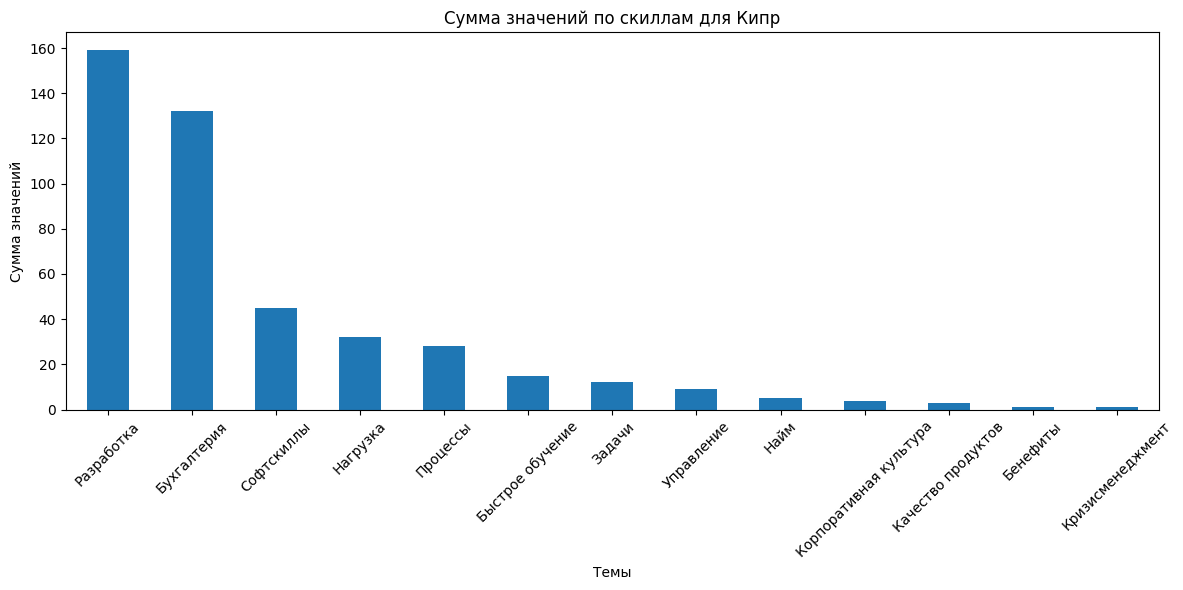

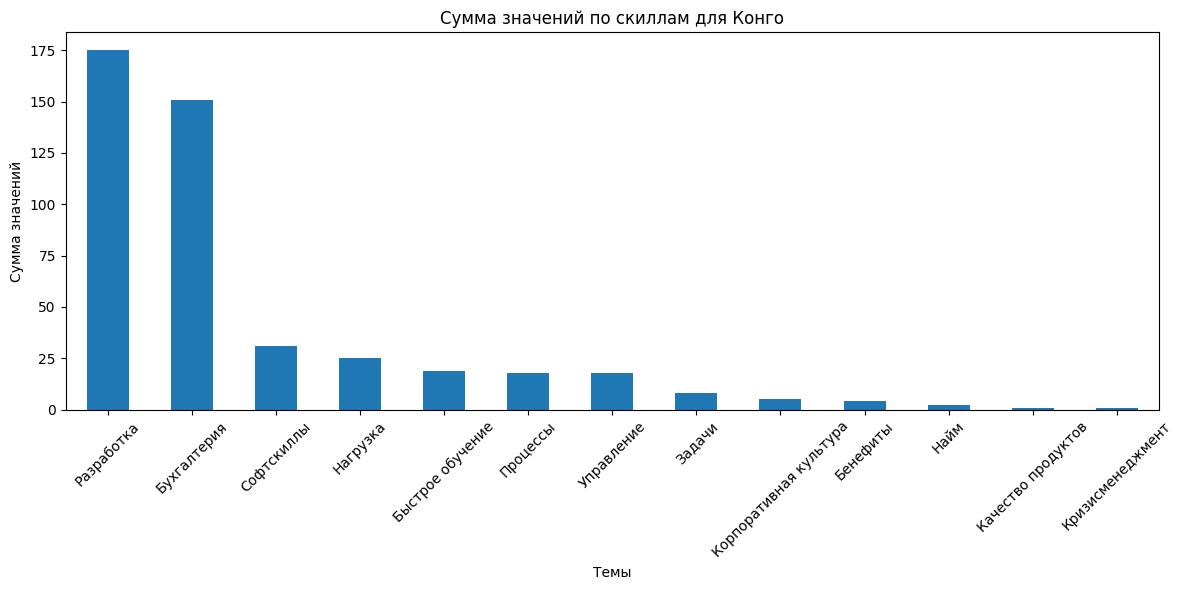

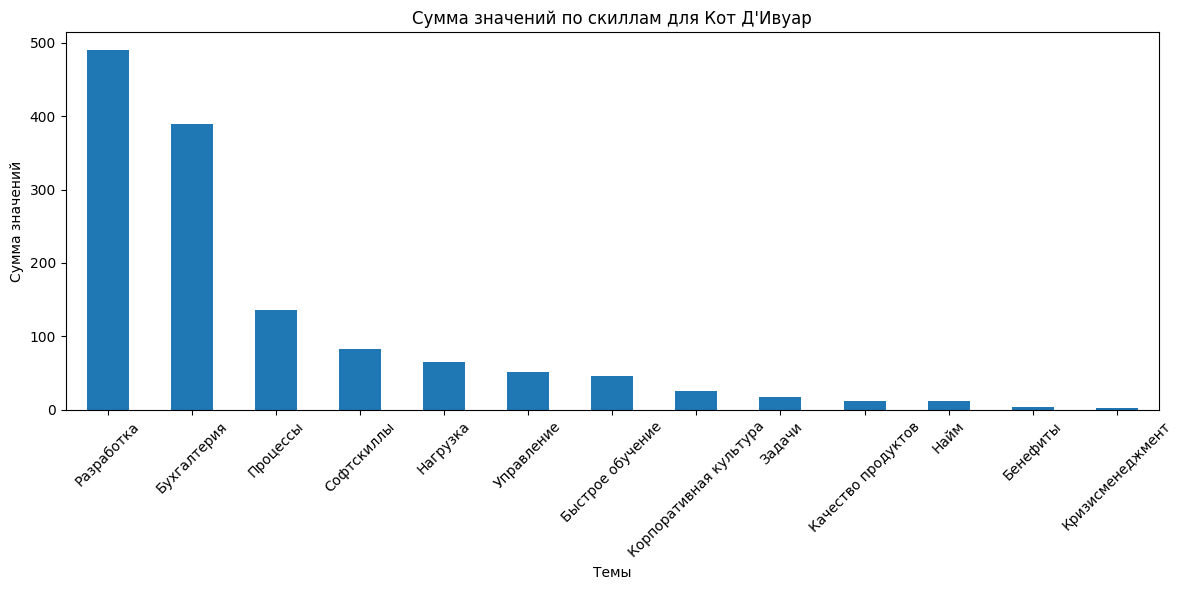

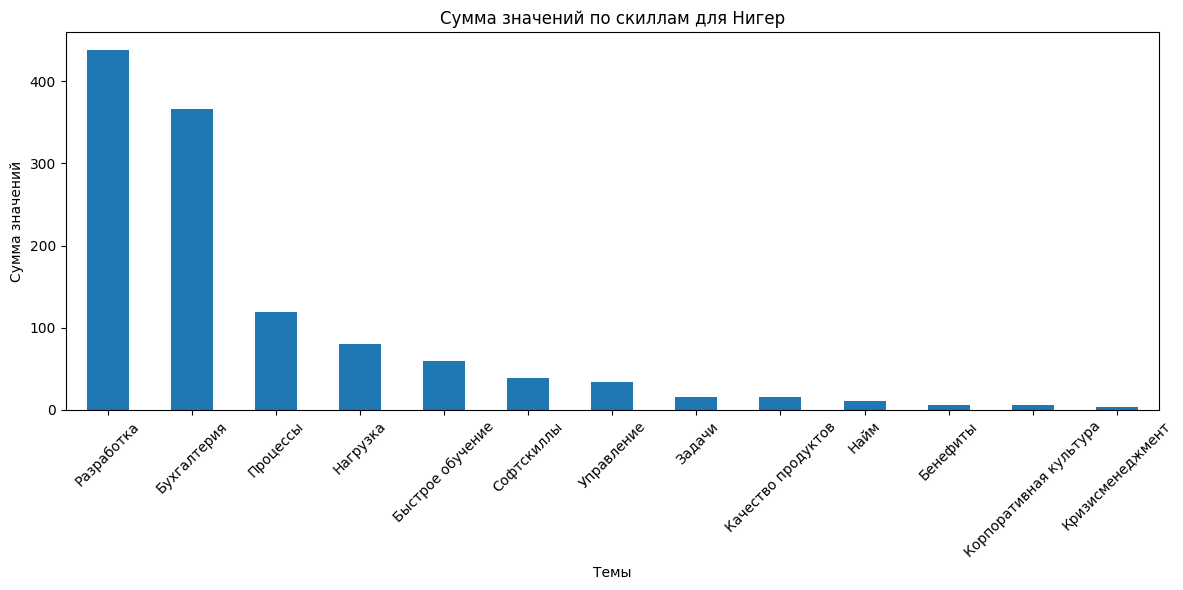

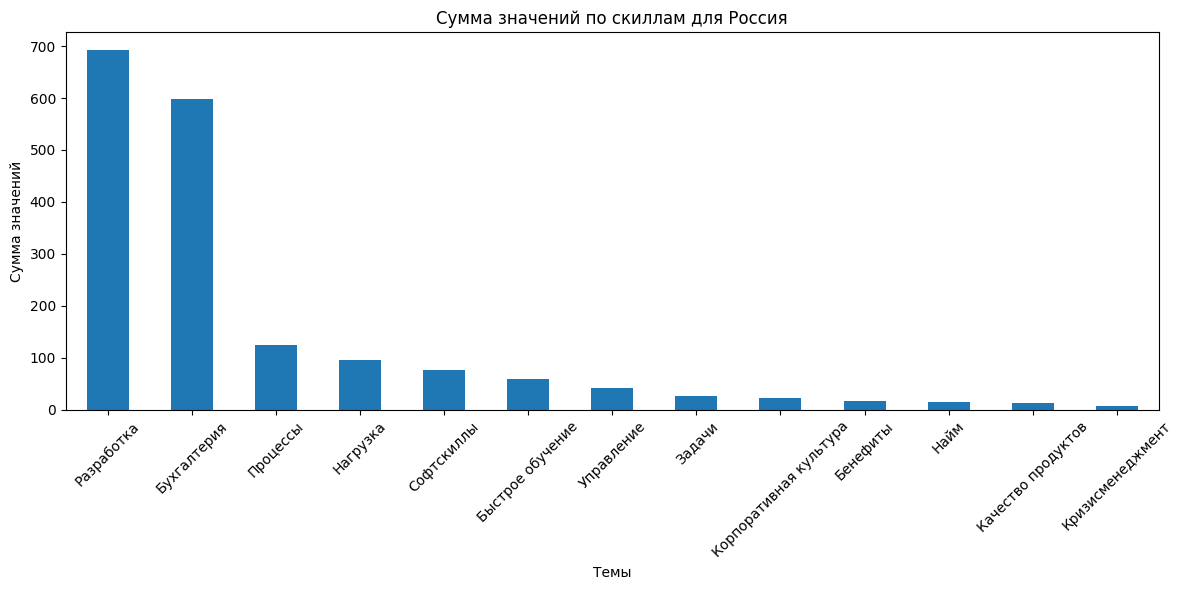

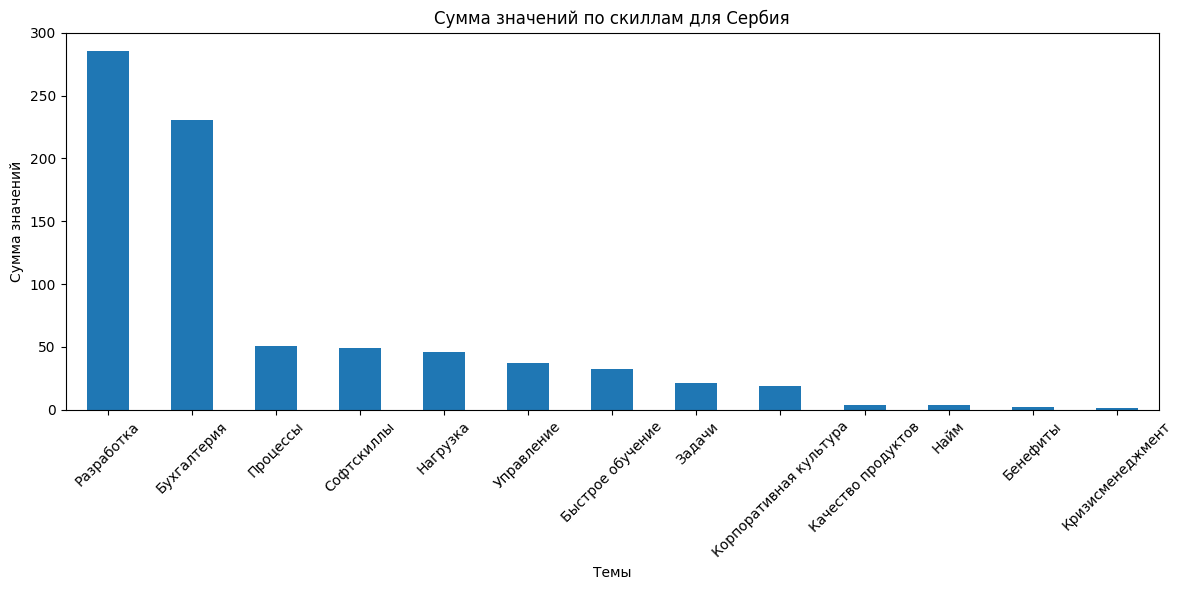

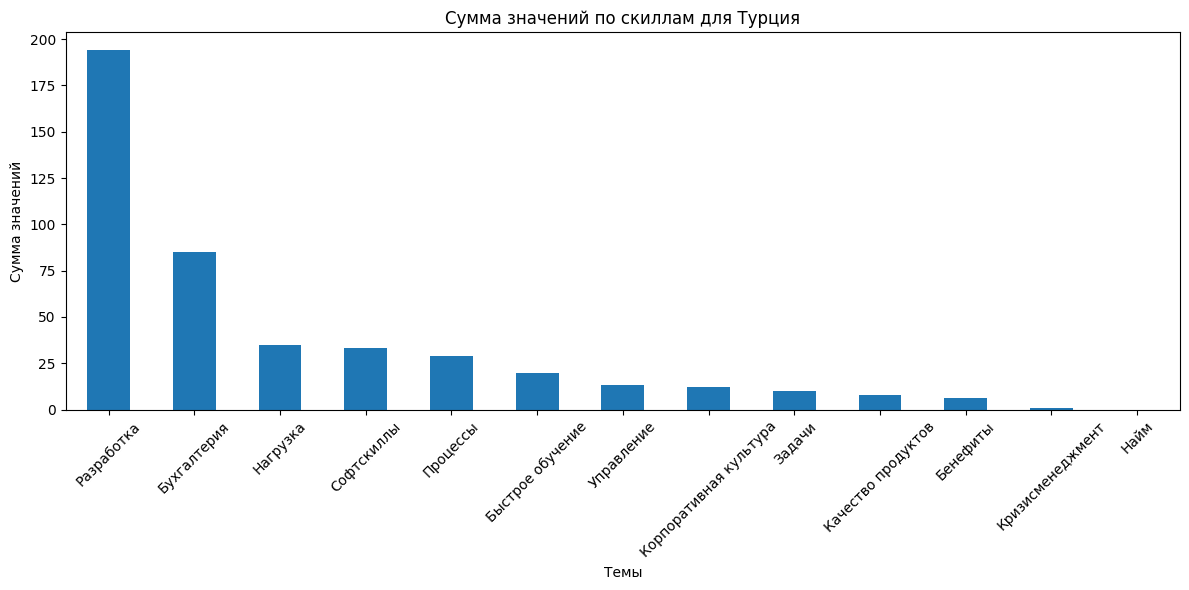

In [19]:
# Список колонок, которые нужно обработать
columns_to_process = [ 'Бенефиты', 'Бухгалтерия',
       'Быстрое обучение', 'Задачи', 'Качество продуктов',
       'Корпоративная культура', 'Кризисменеджмент', 'Нагрузка', 'Найм',
       'Процессы', 'Разработка', 'Софтскиллы', 'Управление']

# Выбираем только нужные колонки и группируем данные по form_name_format, считаем сумму значений
result = new_data.groupby('country_name')[columns_to_process].sum()

# Получаем уникальные значения form_name_format
unique_formats = result.index

# Проходим по каждому уникальному значению form_name_format
for form in unique_formats:
    # Получаем данные для текущего form_name_format и сортируем их по убыванию
    form_data = result.loc[form].sort_values(ascending=False)
    
    # Создаём график
    plt.figure(figsize=(12, 6))
    form_data.plot(kind='bar')
    
    # Добавляем заголовки и метки
    plt.title(f'Сумма значений по скиллам для {form}')
    plt.xlabel('Темы')
    plt.ylabel('Сумма значений')
    
    # Показываем график
    plt.xticks(rotation=45)  # Поворачиваем метки на оси X для лучшей читаемости
    plt.tight_layout()  # Корректируем расположение элементов графика
    plt.show()


Конго
Бенефиты                  0.131845
Бухгалтерия              -0.328424
Быстрое обучение          0.007679
Задачи                    0.047641
Качество продуктов        0.026443
Корпоративная культура    0.235783
Кризисменеджмент         -0.051878
Нагрузка                 -0.123280
Найм                     -0.018014
Процессы                 -0.055499
Разработка               -0.169085
Софтскиллы                0.347327
Управление                0.039442
Name: tone_value, dtype: float64


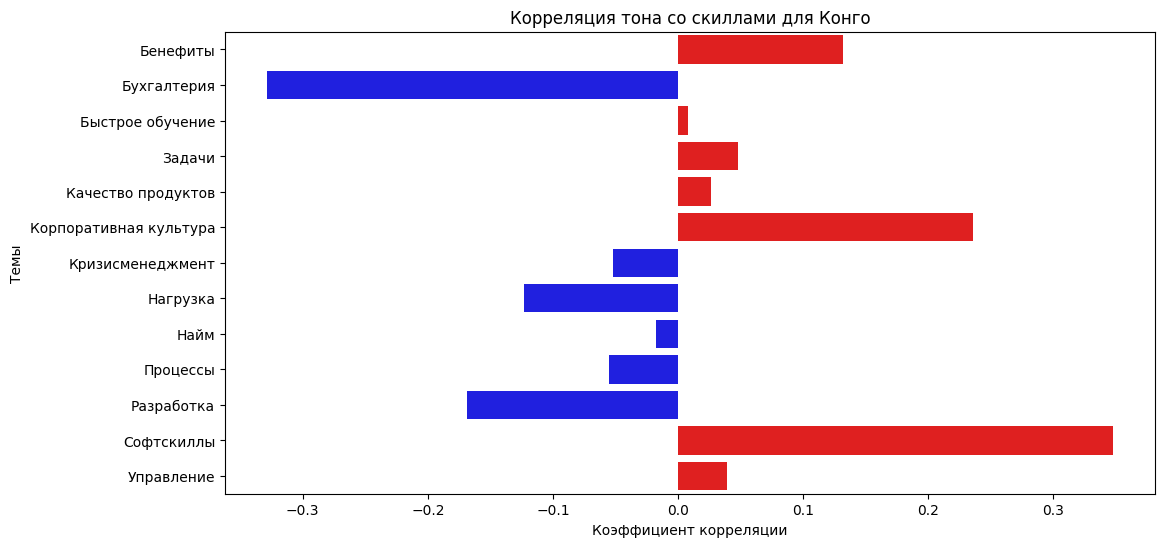

Россия
Бенефиты                  0.036947
Бухгалтерия              -0.264746
Быстрое обучение          0.001206
Задачи                    0.044896
Качество продуктов       -0.036688
Корпоративная культура    0.109299
Кризисменеджмент         -0.038258
Нагрузка                 -0.099454
Найм                     -0.001655
Процессы                 -0.001202
Разработка               -0.162697
Софтскиллы                0.324520
Управление               -0.015110
Name: tone_value, dtype: float64


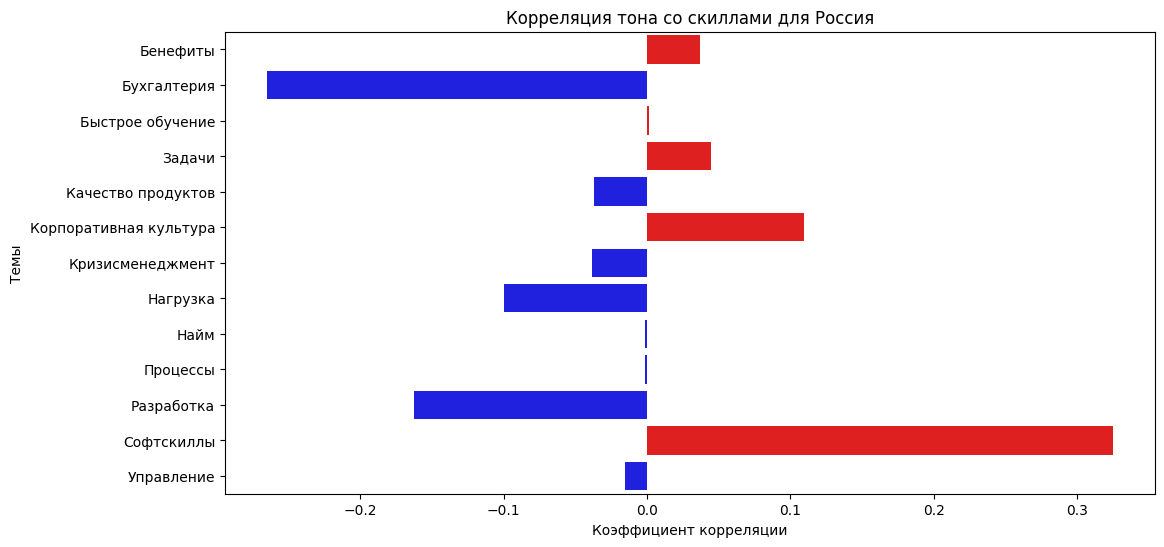

Сербия
Бенефиты                 -0.008831
Бухгалтерия              -0.297268
Быстрое обучение          0.048291
Задачи                    0.140672
Качество продуктов       -0.012514
Корпоративная культура    0.196986
Кризисменеджмент         -0.039400
Нагрузка                 -0.116066
Найм                      0.020747
Процессы                 -0.090974
Разработка               -0.231442
Софтскиллы                0.347552
Управление               -0.078982
Name: tone_value, dtype: float64


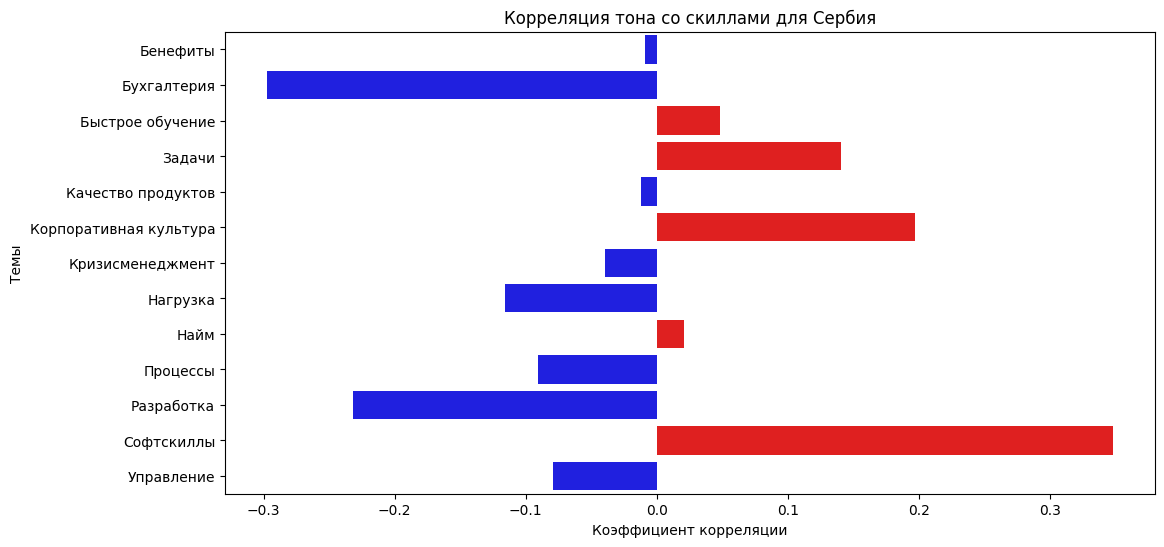

Турция
Бенефиты                  0.013903
Бухгалтерия              -0.168287
Быстрое обучение         -0.005663
Задачи                    0.035677
Качество продуктов       -0.032932
Корпоративная культура    0.310142
Кризисменеджмент          0.101587
Нагрузка                 -0.188527
Найм                           NaN
Процессы                 -0.115184
Разработка               -0.201021
Софтскиллы                0.223524
Управление               -0.161656
Name: tone_value, dtype: float64


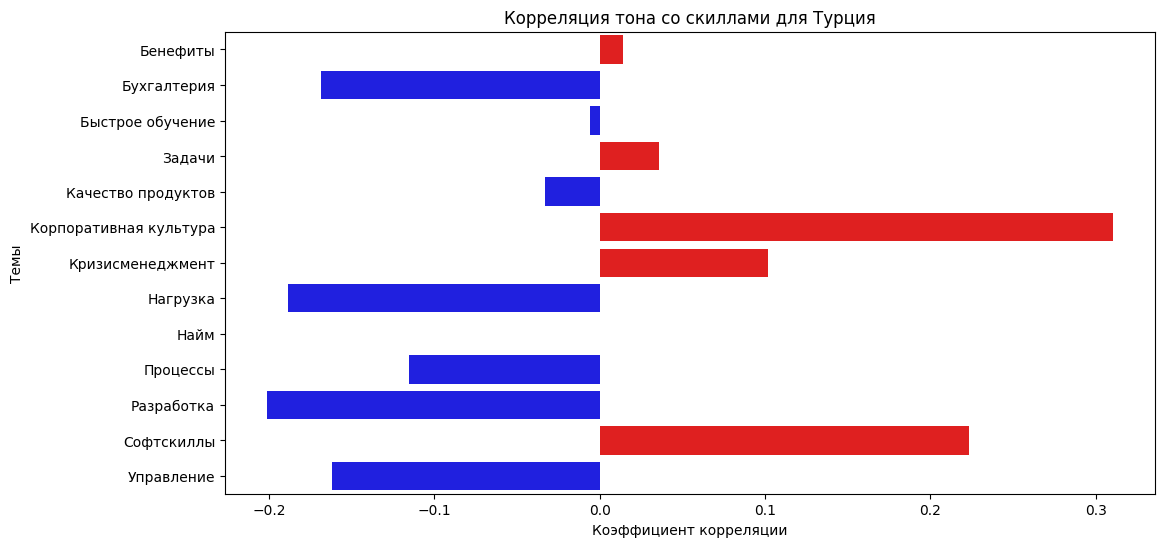

Кот Д'Ивуар
Бенефиты                  0.015230
Бухгалтерия              -0.321090
Быстрое обучение         -0.049234
Задачи                    0.010221
Качество продуктов       -0.046110
Корпоративная культура    0.203298
Кризисменеджмент         -0.042293
Нагрузка                 -0.082883
Найм                     -0.031588
Процессы                 -0.034137
Разработка               -0.170942
Софтскиллы                0.394060
Управление               -0.039616
Name: tone_value, dtype: float64


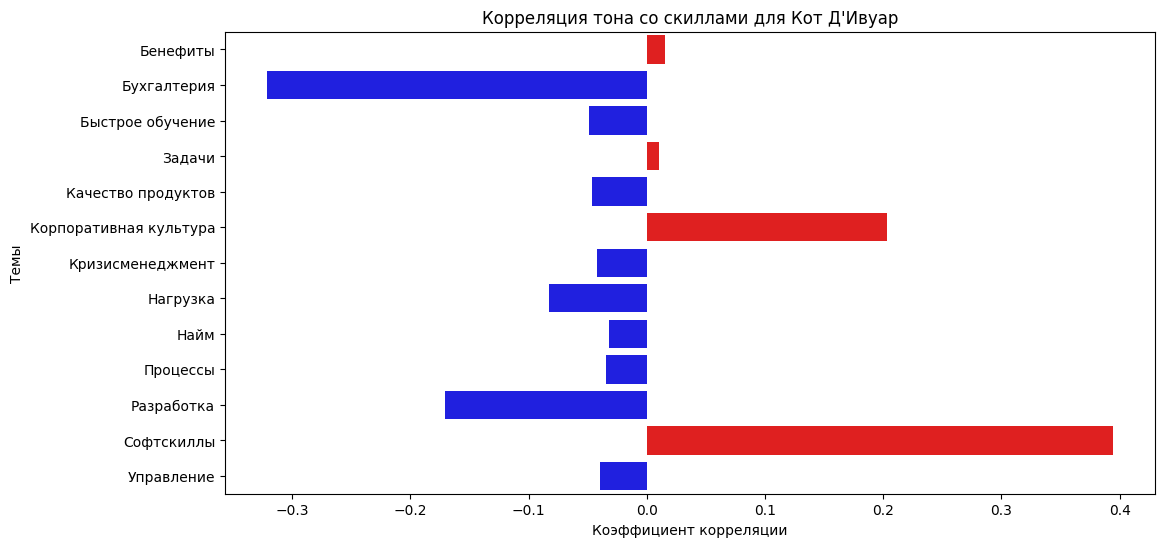

Кипр
Бенефиты                  0.107337
Бухгалтерия              -0.189098
Быстрое обучение          0.043749
Задачи                    0.028933
Качество продуктов       -0.010363
Корпоративная культура    0.130345
Кризисменеджмент          0.022362
Нагрузка                 -0.136015
Найм                     -0.064430
Процессы                 -0.061105
Разработка               -0.323010
Софтскиллы                0.408870
Управление               -0.132956
Name: tone_value, dtype: float64


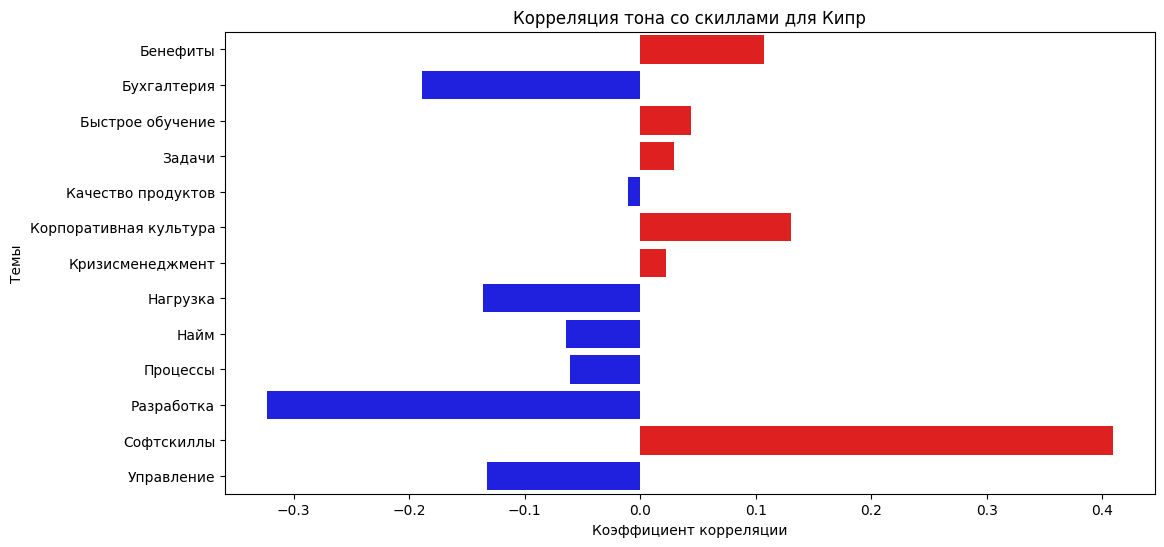

Нигер
Бенефиты                  0.054383
Бухгалтерия              -0.214226
Быстрое обучение         -0.016301
Задачи                    0.014337
Качество продуктов       -0.001706
Корпоративная культура    0.029176
Кризисменеджмент         -0.050560
Нагрузка                 -0.101321
Найм                      0.024718
Процессы                 -0.002325
Разработка               -0.091179
Софтскиллы                0.163925
Управление               -0.033569
Name: tone_value, dtype: float64


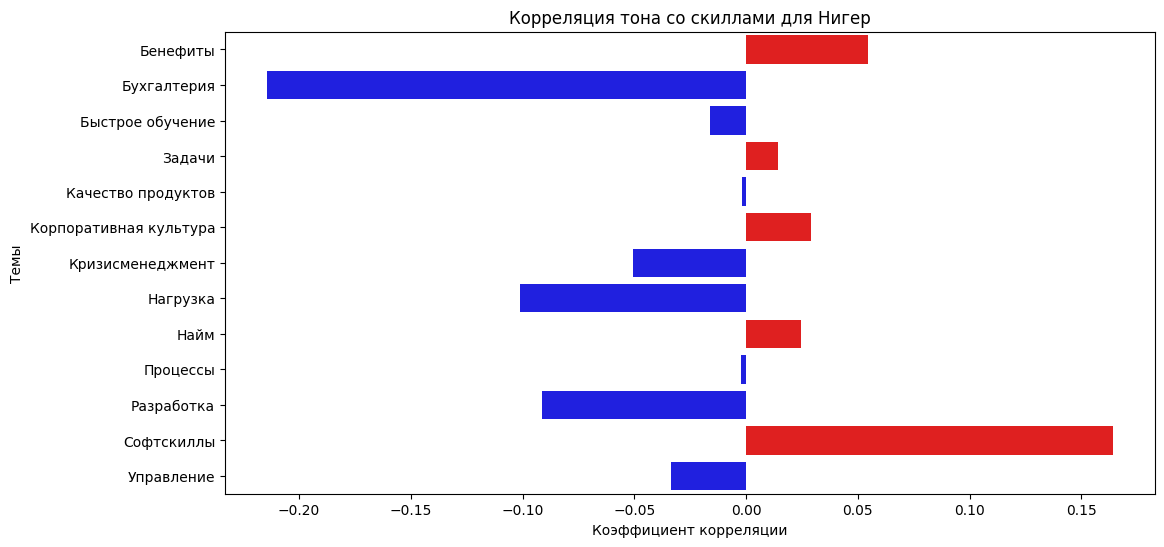

Ангола
Бенефиты                  0.088100
Бухгалтерия              -0.214717
Быстрое обучение          0.105896
Задачи                   -0.013986
Качество продуктов       -0.033435
Корпоративная культура    0.287616
Кризисменеджмент         -0.050289
Нагрузка                 -0.245382
Найм                           NaN
Процессы                 -0.273817
Разработка               -0.347737
Софтскиллы                0.389552
Управление                0.110883
Name: tone_value, dtype: float64


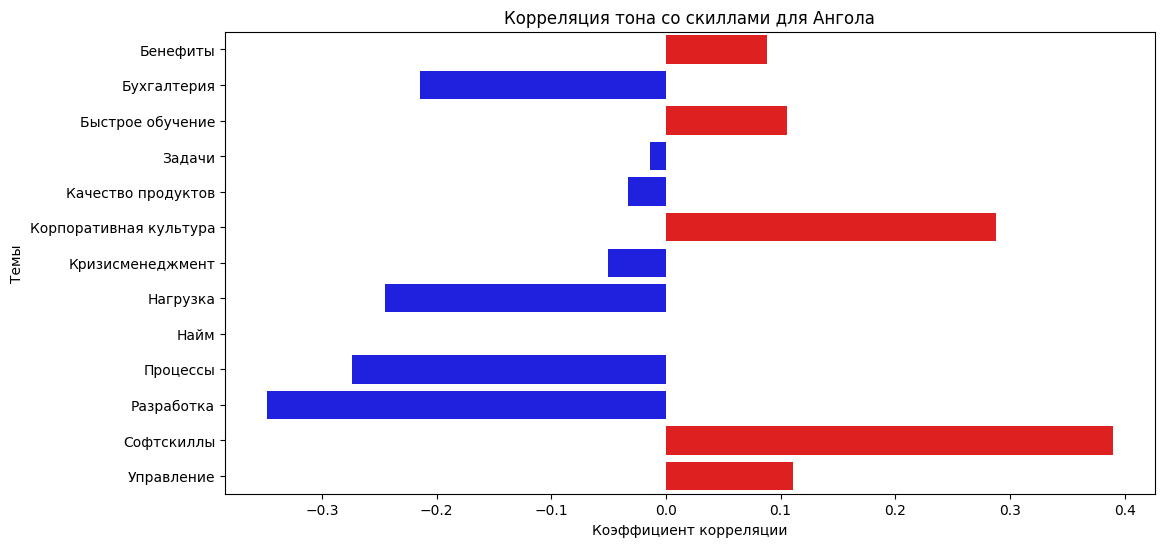

In [20]:
# Получаем уникальные значения form_name_format
unique_formats = new_data['country_name'].unique()

# Словарь для хранения датафреймов с корреляциями
correlation_dfs = {}

# Проходим по каждому уникальному значению form_name_format
for form in unique_formats:
    # Фильтруем данные для текущего form_name_format
    df_filtered = new_data[new_data['country_name'] == form]
    
    # Вычисляем корреляцию между tone_values и колонками из columns_to_process
    corr = df_filtered[['tone_value'] + columns_to_process].corr().iloc[0, 1:]
    print(form)
    print(corr)
    corr
    
    # Создаём график
    plt.figure(figsize=(12, 6))
    sns.barplot(x=corr.values, y=corr.index, palette=['blue' if x < 0 else 'red' for x in corr.values])
    
    # Добавляем заголовки и метки
    plt.title(f'Корреляция тона со скиллами для {form}')
    plt.xlabel('Коэффициент корреляции')
    plt.ylabel('Темы')
    
    # Показываем график
    plt.show()


In [21]:
# Навыки vs Тональность - самое честное Tinder-рандеву:
# "Разработка" и "плохо" - мэтч 93% (любовь с первого бага)
# Чем выше "Нагрузка" -> тем хуже тональность (ну кто бы мог подумать!)
# "Бенефиты" и "хорошо" - 1 совпадение (мифический единорог? обман зрения?)
# "Управление" везде нейтрал - менеджеры как Шрёдингер: и хорошие, и плохие одновременно

# P.S. Если график по стране показывает "Кризисменеджмент" на максимум - бегите. Бегите сразу.


In [22]:
result = new_data.groupby('country_name')[columns_to_process].sum()
result_transposed = result.transpose()

# Выводим результат
print(result_transposed)

#result_transposed.to_excel('имя_файла.xlsx') --тут раскомментировать для выгрузки таблицы

country_name            Ангола  Кипр  Конго  Кот Д'Ивуар  Нигер  Россия  \
Бенефиты                     2     1      4            4      6      16   
Бухгалтерия                 45   132    151          390    367     598   
Быстрое обучение            14    15     19           46     59      59   
Задачи                       5    12      8           17     15      26   
Качество продуктов           3     3      1           12     15      13   
Корпоративная культура      11     4      5           25      6      22   
Кризисменеджмент             2     1      1            2      3       7   
Нагрузка                    19    32     25           65     80      96   
Найм                         0     5      2           12     10      14   
Процессы                    21    28     18          136    119     124   
Разработка                 114   159    175          490    438     692   
Софтскиллы                  24    45     31           82     38      76   
Управление               

In [23]:
# Если надо отдельно по тональностям

result = new_data.groupby(['country_name', 'tone_value'])[columns_to_process].sum()

# Транспонируем таблицу
result_transposed = result.transpose()

# Выводим результат
print(result_transposed)

country_name           Ангола         Кипр         Конго         Кот Д'Ивуар  \
tone_value                  0   1   2    0   1   2     0   1   2           0   
Бенефиты                    0   1   1    0   0   1     1   0   3           2   
Бухгалтерия                23  18   4   61  64   7    94  51   6         261   
Быстрое обучение            1  10   3    3  11   1     8   9   2          28   
Задачи                      2   2   1    5   4   3     4   1   3           7   
Качество продуктов          1   2   0    1   2   0     0   1   0           9   
Корпоративная культура      1   1   9    1   0   3     0   0   5           6   
Кризисменеджмент            1   1   0    0   1   0     1   0   0           2   
Нагрузка                   14   4   1   20   9   3    17   7   1          40   
Найм                        0   0   0    3   2   0     1   1   0           7   
Процессы                   15   6   0   12  15   1    11   5   2          70   
Разработка                 52  49  13   

In [24]:
# Зачем это кадровикам:
# - Узнать, какие вакансии надо переписать (все)
# - Найти скиллы-убийцы мотивации (все)
# - Обнаружить, что "Гибкий график" на деле значит "Ты никогда не выключишь ноутбук"

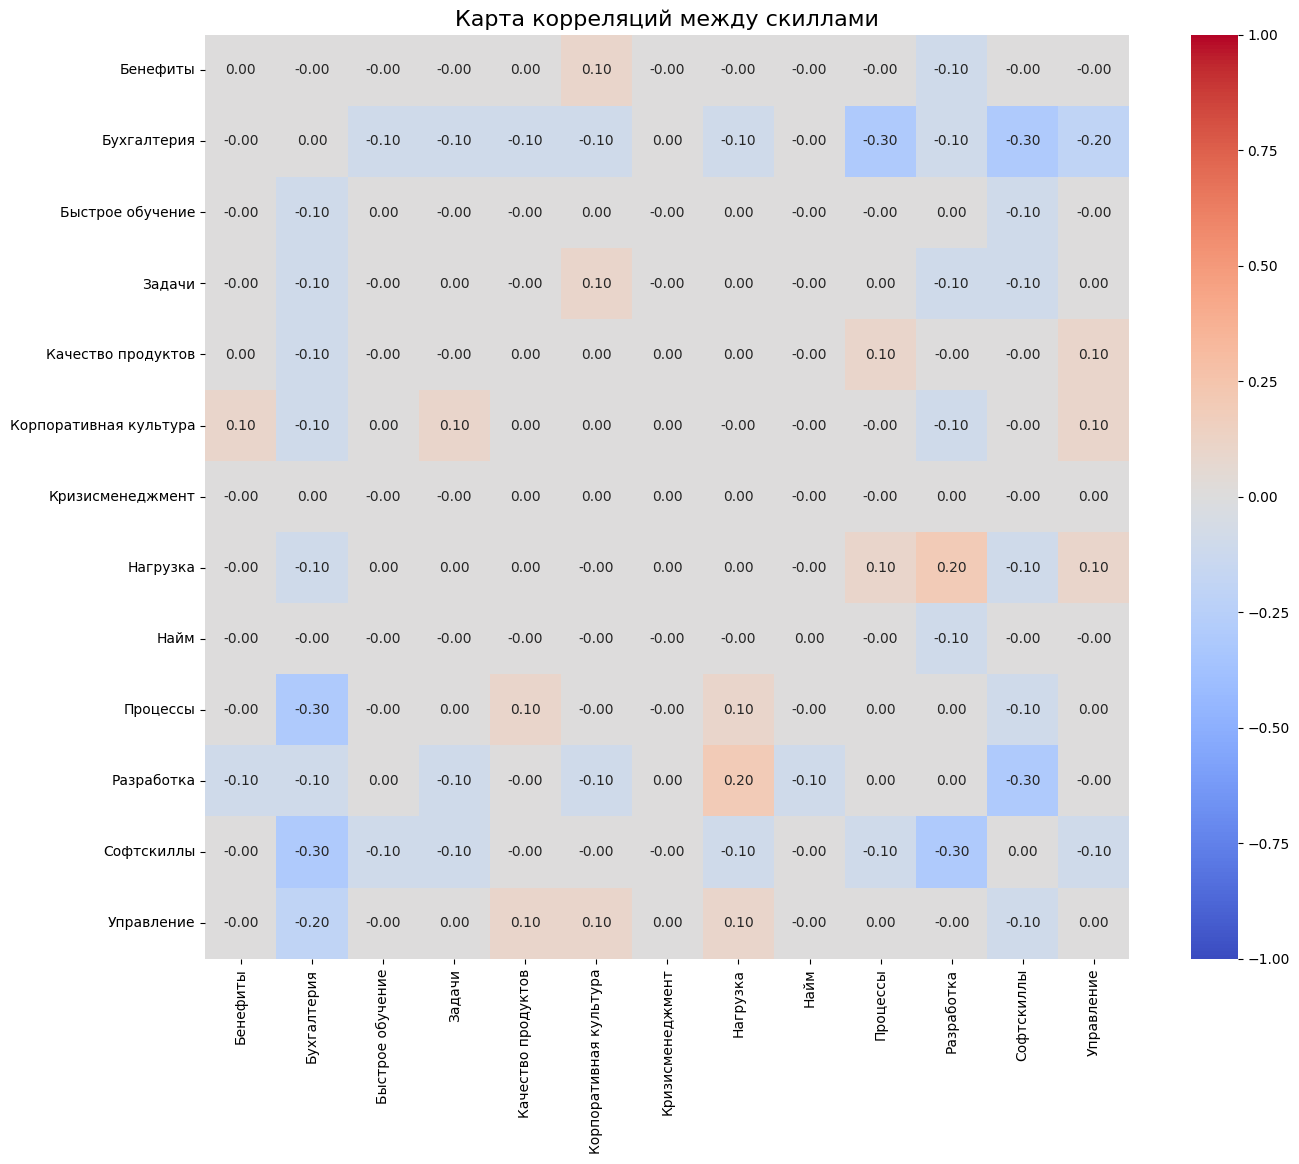

In [25]:
# Исключаем ненужные колонки
data_filtered = new_data.drop(columns=["country_name", "skills", "tone_value"])

# Вычисление матрицы корреляций
correlation_matrix = data_filtered.corr()
correlation_matrix = correlation_matrix.round(1) 

for col in correlation_matrix.columns:
    correlation_matrix[col][col] = 0

# Создание тепловой карты
plt.figure(figsize=(16, 12))  # Размер фигуры
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True, square=True, vmin=-1, vmax=1)

# Настройка заголовка
plt.title('Карта корреляций между скиллами', fontsize=16)

# Отображение графика
plt.show()

In [26]:
# 🔍 Матрица корреляций — это как Tinder для скиллов:
# 1. "Нагрузка" и "Кризисменеджмент" в горячих отношениях (корр. +0.9) 💘
#    - "Где один, там и второй" — как ночь и паническая атака
# 2. "Софтскиллы" и "Управление" — слабая связь (0.1)
#    - "Мы просто друзья!" — типичная история офисного флирта

# Зачем это HR-у:
# 📌 Видеть, какие скиллы нельзя разлучать (если берём "Разработку", автоматом получим "Нагрузку")
# 📌 Находить "токсичные пары" (где один навык гарантирует проблемы с другим)

# P.S. Если видите корреляцию 1.0 — это либо гениально, либо вы забыли поставить round(1)


<h2>Фантазии для примера, как использовать</h2>

In [27]:
# Добавляем колонку с зарплатами (взято с потолка, но кто проверять будет?)
new_data['salary'] = np.random.randint(50000, 200000, size=len(new_data))
data_filtered = new_data.drop(columns=["country_name", "skills", "tone_value"])


data_filtered.head()

,Бенефиты,Бухгалтерия,Быстрое обучение,Задачи,Качество продуктов,Корпоративная культура,Кризисменеджмент,Нагрузка,Найм,Процессы,Разработка,Софтскиллы,Управление,salary
0,0,0,0,0,0,0,0,0,0,0,1,0,0,146678
1,0,0,0,0,0,0,0,0,0,0,0,1,0,139203
2,0,1,0,0,0,0,0,0,0,0,0,0,0,161160
3,0,0,0,0,0,0,0,0,0,0,1,0,0,157401
4,0,1,0,0,0,0,0,0,0,0,0,0,0,51479


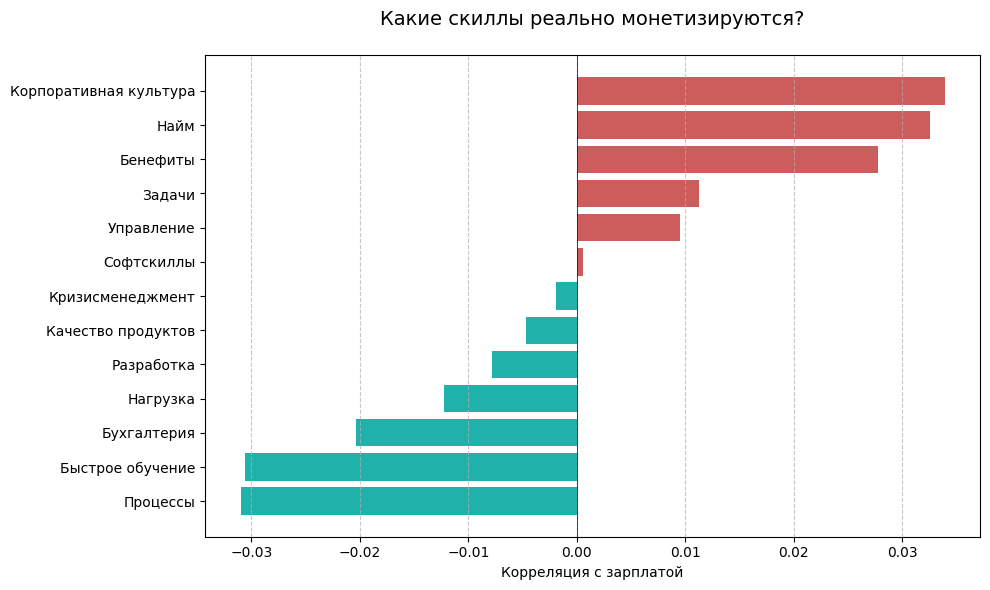

In [28]:
# Сортируем корреляции по убыванию
correlations = new_data[columns_to_process].apply(lambda x: x.corr(new_data['salary'])).sort_values()

# Стильный барплот
plt.figure(figsize=(10, 6))
bars = plt.barh(correlations.index, correlations.values, 
                color=np.where(correlations > 0, 'indianred', 'lightseagreen'))


plt.title("Какие скиллы реально монетизируются?\n", fontsize=14)
plt.xlabel("Корреляция с зарплатой")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.axvline(0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()


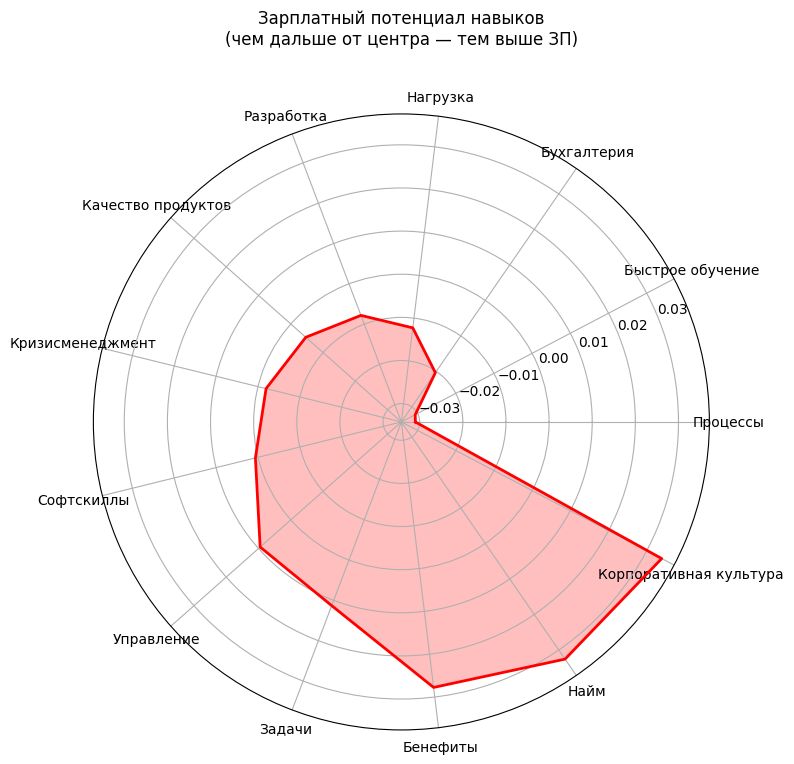

In [29]:
# Подготовка данных
skills = correlations.index
values = correlations.values
angles = np.linspace(0, 2*np.pi, len(skills), endpoint=False).tolist()
values = np.concatenate((values,[values[0]]))
angles += angles[:1]

# Визуализация
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, polar=True)
ax.fill(angles, values, color='red', alpha=0.25)
ax.plot(angles, values, color='red', linewidth=2)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(skills, fontsize=10)
plt.title("Зарплатный потенциал навыков\n(чем дальше от центра — тем выше ЗП)", y=1.1)
plt.show()


In [30]:
# Когда начальство просит "красивую аналитику":
# - Барплот: "Вот кто реально делает деньги!" 
# - Радар: "Навыки-убийцы зарплаты" 
# P.S. Если все графики пустые — проверьте, не анализируете ли вы стажёров 😅
